1.Inspect the shape, columns, sample rows, and data types.

In [2]:
#Importing the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
#Making the model read the dataset
df = pd.read_csv("/content/automobile_dataset-selected-columns.csv")

In [5]:
#Checking the number of rows and columns
df.shape

(5500, 11)

Rows = 5500
  Columns = 11

In [6]:
#For getting all the names of the column elements
df.columns

Index(['Make', 'Model', 'Year', 'Fuel_Type', 'Transmission', 'Mileage',
       'Horsepower', 'Torque', 'Color', 'Fuel_Efficiency', 'Selling_Price'],
      dtype='object')

In [7]:
#For getting the Sample rows in dataset
#First 5 Rows
df.head()

,Make,Model,Year,Fuel_Type,Transmission,Mileage,Horsepower,Torque,Color,Fuel_Efficiency,Selling_Price
0,Mercedes-Benz,GLE,2024,Petrol,Automatic,100,186.0,196.0,Silver,30.0,64140
1,Hyundai,Tucson,2008,Petrol,Automatic,387035,189.0,190.0,Blue,35.0,500
2,Volkswagen,Golf,2021,Hybrid,NaN,46054,158.0,153.0,Gray,43.0,16429
3,Chevrolet,Tahoe,2005,Petrol,NaN,141302,169.0,165.0,Blue,NaN,2199
4,Toyota,Camry,2022,Petrol,Automatic,32813,149.0,141.0,Brown,38.0,21792


In [8]:
#Last 5 Rows
df.tail()

,Make,Model,Year,Fuel_Type,Transmission,Mileage,Horsepower,Torque,Color,Fuel_Efficiency,Selling_Price
5495,Volkswagen,Tiguan,2022,Petrol,Automatic,29506,161.0,NaN,Black,33.0,20333
5496,Nissan,Pathfinder,2006,Petrol,Automatic,287332,243.0,227.0,Gray,NaN,500
5497,BMW,X3,2013,Petrol,Automatic,95961,171.0,152.0,Blue,32.0,9882
5498,Volkswagen,Golf,2020,Hybrid,Automatic,56643,135.0,125.0,White,57.0,10474
5499,Chevrolet,Tahoe,2011,Petrol,Automatic,169929,168.0,158.0,Gray,NaN,6193


In [9]:
#Information of the datatypes in the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Make             5500 non-null   object 
 1   Model            5500 non-null   object 
 2   Year             5500 non-null   int64  
 3   Fuel_Type        5500 non-null   object 
 4   Transmission     4673 non-null   object 
 5   Mileage          5500 non-null   int64  
 6   Horsepower       4700 non-null   float64
 7   Torque           4701 non-null   float64
 8   Color            4697 non-null   object 
 9   Fuel_Efficiency  4706 non-null   float64
 10  Selling_Price    5500 non-null   int64  
dtypes: float64(3), int64(3), object(5)
memory usage: 472.8+ KB


2. Check missing values, duplicates, and inconsistent categories.

In [10]:
#Check for Missing Values
df.isnull().sum()

,0
Make,0
Model,0
Year,0
Fuel_Type,0
Transmission,827
Mileage,0
Horsepower,800
Torque,799
Color,803
Fuel_Efficiency,794


In [11]:
#Total Misssing Values
df.isnull().sum().sum()

np.int64(4023)

Missing values = 4023

In [12]:
#Checking duplicated rows
df.duplicated().sum()

np.int64(0)

There are no duplicated rows in this dataset

3.Clean the dataset and explain each important decision.

In [14]:
#There are two ways of treat missing values:
#1.Delete missing values
#2.Replace missing values

#Replacing the missing values

#Numerical columns - Median Imputation
df['Horsepower'].fillna(df['Horsepower'].median())
df['Torque'].fillna(df['Torque'].median())
df['Fuel_Efficiency'].fillna(df['Fuel_Efficiency'].median())

#Categorical columns - Unknown Imputation
df['Transmission'].fillna('Unknown')
df['Color'].fillna('Unknown')

,Color
0,Silver
1,Blue
2,Gray
3,Blue
4,Brown
...,...
5495,Black
5496,Gray
5497,Blue
5498,White


In [17]:
#Verify the missing values
print("Missing values after treatment:\n")
print(df.isnull().sum())

Missing values after treatment:

Make               0
Model              0
Year               0
Fuel_Type          0
Transmission       0
Mileage            0
Horsepower         0
Torque             0
Color              0
Fuel_Efficiency    0
Selling_Price      0
dtype: int64


There are no missing values after treatment

In [18]:
#To check categorical data is replace by 'Unknown'
df['Color'].value_counts()

,count
Color,
Unknown,803
Brown,624
Black,610
Red,602
Green,590
Blue,589
Gray,587
Silver,550
White,545


This means there are 803 missing values in colour column

4. Calculate descriptive statistics for numerical and categorical columns.

In [19]:
#Descriptive Statistics
#To get the mean,standard deviation, minimum, maximum and quartiles

#For Numerical columns
df.describe()

,Year,Mileage,Horsepower,Torque,Fuel_Efficiency,Selling_Price
count,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000
mean,2014.494000,114529.481636,196.602182,187.414545,33.865091,12319.873636
std,5.789745,91858.943421,51.621268,52.499359,13.974959,12658.478862
min,2005.000000,100.000000,97.000000,77.000000,10.000000,500.000000
25%,2009.000000,39112.000000,165.000000,156.000000,28.000000,1304.750000
50%,2014.000000,96926.500000,187.000000,178.000000,32.000000,8586.000000
75%,2020.000000,172757.500000,223.000000,212.000000,36.000000,19097.500000
max,2024.000000,536731.000000,434.000000,443.000000,141.000000,86692.000000


In [20]:
#For categorical columns
df.describe(include = 'object')

,Make,Model,Fuel_Type,Transmission,Color
count,5500,5500,5500,5500,5500
unique,10,40,4,3,9
top,Hyundai,GLE,Petrol,Automatic,Unknown
freq,579,166,4267,4142,803


5.Perform univariate, bivariate, and multivariate analysis.

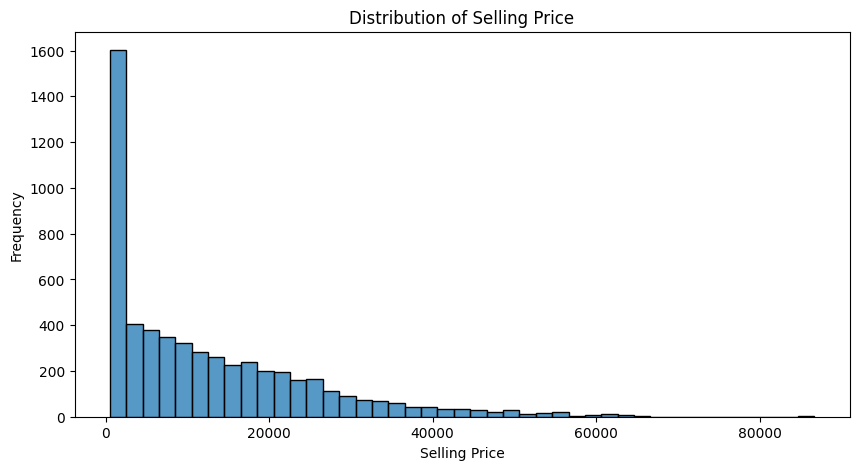

In [23]:
#1.Univariate Analysis
#A) Selling Price Distribution = It shows how many cars are sold in particular price pool
plt.figure(figsize=(10,5))

sns.histplot(df['Selling_Price'])
plt.title('Distribution of Selling Price')
plt.xlabel('Selling Price')
plt.ylabel('Frequency') #Here frequency = no of cars

plt.show()


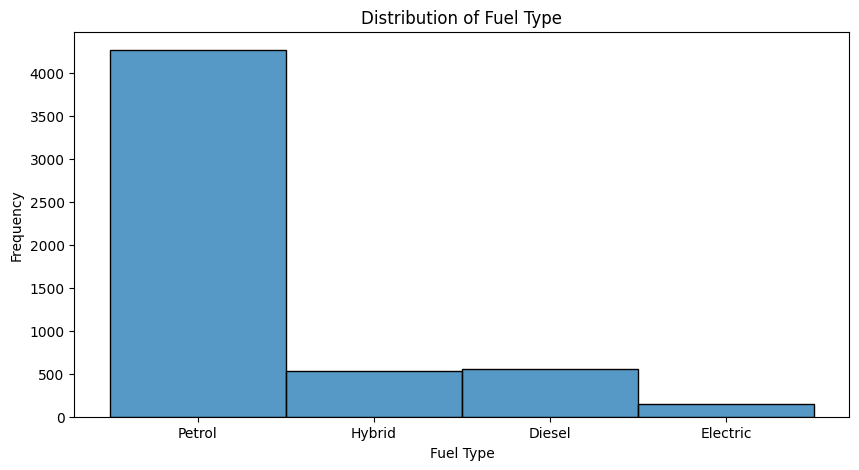

In [24]:
#B. Fuel Type Distribution
plt.figure(figsize =(10,5))

sns.histplot(df['Fuel_Type'])
plt.title('Distribution of Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Frequency')
plt.show()

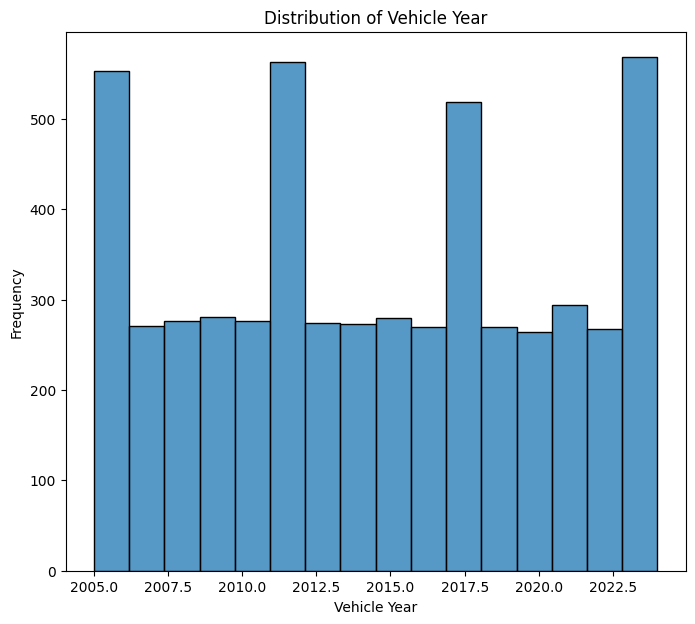

In [49]:
#C. Vehicle Year Distribution
plt.figure(figsize = (8,7))

sns.histplot(df['Year'])
plt.title('Distribution of Vehicle Year')
plt.xlabel('Vehicle Year')
plt.ylabel('Frequency')
plt.show()

<Figure size 800x500 with 0 Axes>

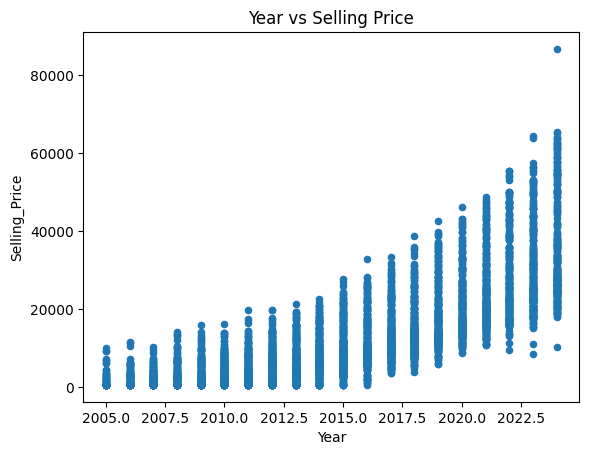

In [34]:
#2.Bivariate Analysis = To check relationship between two columns
#A.Year vs Selling Price
plt.figure(figsize = (8,5))

df.plot(kind = "scatter",x = "Year",y = "Selling_Price")
plt.title('Year vs Selling Price')
plt.show()



<Figure size 800x500 with 0 Axes>

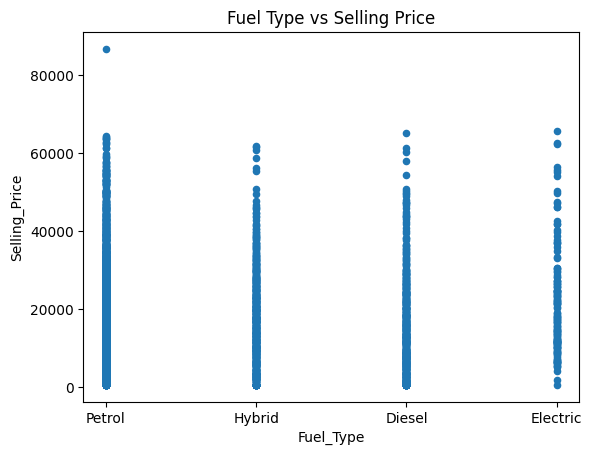

In [35]:
#B.Fuel Type vs Selling Price
plt.figure(figsize = (8,5))

df.plot(kind = "scatter",x = "Fuel_Type", y = "Selling_Price")
plt.title('Fuel Type vs Selling Price')
plt.show()

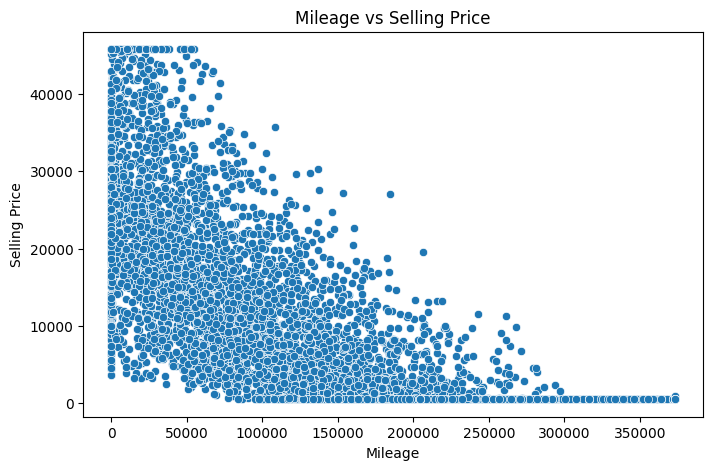

In [48]:
#C.Mileage v/s Selling Price
plt.figure(figsize=(8,5))

sns.scatterplot(x=df['Mileage'],y=df['Selling_Price'])

plt.title('Mileage vs Selling Price')
plt.xlabel('Mileage')
plt.ylabel('Selling Price')

plt.show()

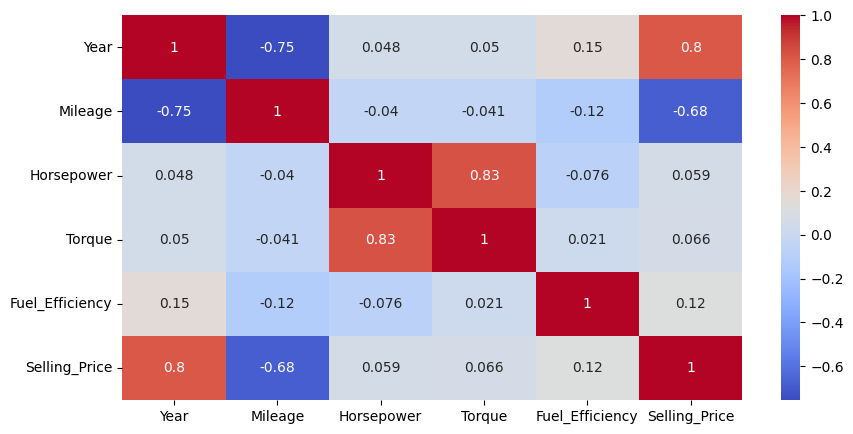

In [38]:
#3.Multivariate Analysis = Gives the relationship of multiple columns
plt.figure(figsize=(10,5))
sns.heatmap(df.corr(numeric_only=True),annot = True, cmap = "coolwarm")
plt.show()


6.Identify outliers, relationships, and at least five useful insights.

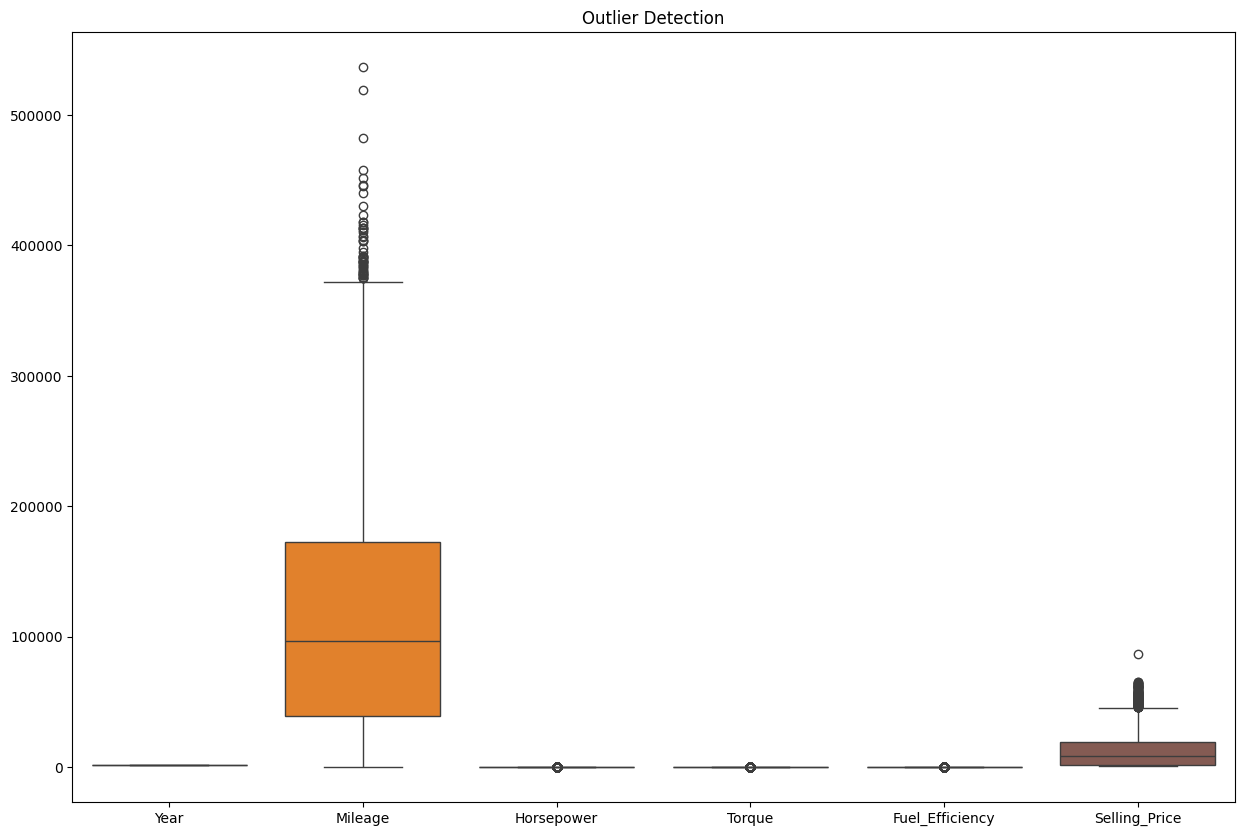

In [42]:
#Outlier Detection
plt.figure(figsize = (15,10))
sns.boxplot(data = df)
plt.title('Outlier Detection')
plt.show()

In [45]:
#Outlier Treatment - Applied only to numeric columns
numeric_cols = df.select_dtypes(include=[np.number]).columns

for col in numeric_cols:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)

  IQR = Q3 - Q1

  lower_limit = Q1 - 1.5 * IQR
  upper_limit = Q3 + 1.5 * IQR

  df[col] = np.where(df[col] < lower_limit, lower_limit, df[col])
  df[col] = np.where(df[col] > upper_limit, upper_limit, df[col])

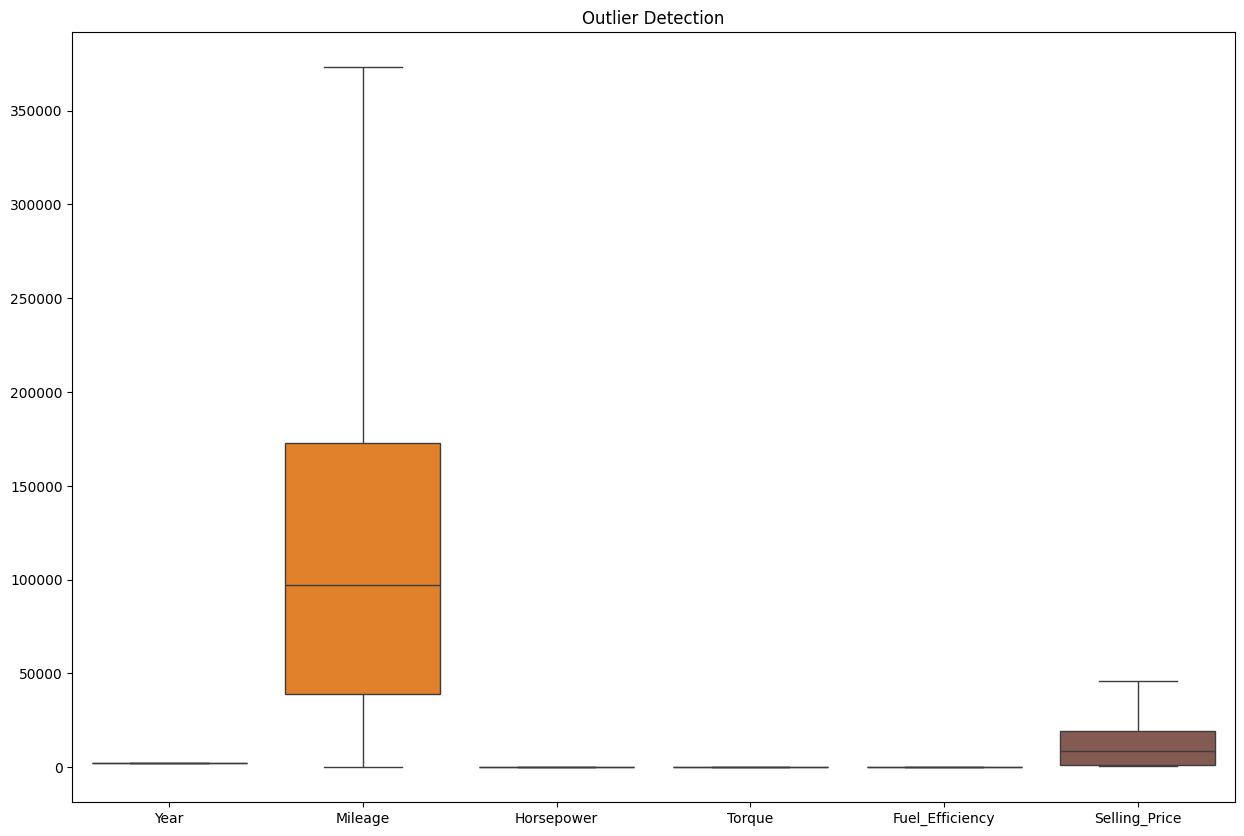

In [46]:
#Reverify
plt.figure(figsize = (15,10))
sns.boxplot(data = df)
plt.title('Outlier Detection')
plt.show()

Useful Insights

Conclusion:

1. The dataset contains 5500 rows and 11 columns.
2. Missing values were handled using median imputation for numerical columns and 'Unknown' for categorical columns.
3. Duplicate records were not found.
4. Univariate, bivariate and multivariate analysis were performed.
5. Correlation analysis showed that Year has a positive relationship with Selling Price, while Mileage has a negative relationship.
6. Outliers were detected using the IQR method and treated using outlier treatment.
7. The dataset shows useful patterns between car features and selling prices.